# Speed Comparison: CKA Libraries vs. Vanilla CPU

Measures wall-clock time of a full CKA computation (ResNet-18 vs. ResNet-18 on the CIFAR-10 test set) for:

1. **pytorch-cka** (this library), on the GPU
2. **torch-cka**, on the GPU
3. **Vanilla CKA**, on the CPU: a plain NumPy implementation of the same minibatch CKA estimator (unbiased HSIC) that pytorch-cka computes, one Gram matrix and one layer pair at a time

For a fair comparison:
- All three compare the **same 18 layers**: the 17 convolutions on ResNet-18's main path plus the final `fc` layer.
- Each run starts with fresh model copies that have identical weights. This keeps hooks left behind by one run from slowing down the next one.
- Each method gets one warm-up run, followed by `N_REPEATS` timed runs with `torch.cuda.synchronize()` around the timer.

In [1]:
!pip install torch torchvision torch-cka pytorch-cka tqdm pandas -q

In [2]:
import gc
import os
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from cka import compute_cka  # pytorch-cka
from torch_cka import CKA as TorchCKA  # torch-cka

In [3]:
# pytorch-cka and torch-cka run on the GPU; the vanilla baseline runs on the CPU.
assert torch.cuda.is_available(), "This benchmark requires a CUDA GPU"
device = torch.device("cuda")
cpu = torch.device("cpu")
print(f"Using device: {torch.cuda.get_device_name(device)}")

N_WARMUP = 1
N_REPEATS = 5
BATCH_SIZE = 1000

Using device: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [4]:
def get_cpu_name():
    """CPU model name, read from /proc/cpuinfo on Linux (e.g. Colab)."""
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


CPU_NAME = get_cpu_name()
print(f"CPU: {CPU_NAME}")
print(f"Logical cores: {os.cpu_count()}")
print(f"PyTorch CPU threads: {torch.get_num_threads()}")

CPU: AMD EPYC 9B45
Logical cores: 48
PyTorch CPU threads: 24


In [5]:
def get_resnet18(num_classes=10):
    """Get ResNet-18 modified for CIFAR-10 (32x32 images)"""
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


# Fix the weights once so that every run of every method sees identical models.
torch.manual_seed(0)
model1_state = get_resnet18().state_dict()
model2_state = get_resnet18().state_dict()


def fresh_models(device):
    """Build new model instances (no leftover hooks) with the fixed weights on `device`."""
    model1 = get_resnet18()
    model1.load_state_dict(model1_state)
    model2 = get_resnet18()
    model2.load_state_dict(model2_state)
    return model1.to(device).eval(), model2.to(device).eval()


# The 18 layers ResNet-18 is named after: 17 main-path convolutions and the final fc layer.
LAYERS = [
    "conv1",
    "layer1.0.conv1",
    "layer1.0.conv2",
    "layer1.1.conv1",
    "layer1.1.conv2",
    "layer2.0.conv1",
    "layer2.0.conv2",
    "layer2.1.conv1",
    "layer2.1.conv2",
    "layer3.0.conv1",
    "layer3.0.conv2",
    "layer3.1.conv1",
    "layer3.1.conv2",
    "layer4.0.conv1",
    "layer4.0.conv2",
    "layer4.1.conv1",
    "layer4.1.conv2",
    "fc",
]
print(f"Number of layers: {len(LAYERS)}")
print(LAYERS)

Number of layers: 18
['conv1', 'layer1.0.conv1', 'layer1.0.conv2', 'layer1.1.conv1', 'layer1.1.conv2', 'layer2.0.conv1', 'layer2.0.conv2', 'layer2.1.conv1', 'layer2.1.conv2', 'layer3.0.conv1', 'layer3.0.conv2', 'layer3.1.conv1', 'layer3.1.conv2', 'layer4.0.conv1', 'layer4.0.conv2', 'layer4.1.conv1', 'layer4.1.conv2', 'fc']


In [6]:
# Setup dataset and dataloader
base_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# Upload the CIFAR-10 Python archive to this path using Colab's Files panel.
import tarfile

test_set = datasets.CIFAR10(root='./data', train=False, download=True, transform=base_transforms)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Dataset size: {len(test_set)}")
print(f"Number of batches: {len(test_loader)}")

100%|██████████| 170M/170M [29:36<00:00, 95.9kB/s]


Dataset size: 10000
Number of batches: 10


In [7]:
def cleanup_memory():
    """Clean up GPU/CPU memory"""
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()


def benchmark(name, run_fn, device, n_warmup=N_WARMUP, n_repeats=N_REPEATS):
    """Time `run_fn(model1, model2)` on fresh models placed on `device`; return timed-run durations in seconds."""
    times = []
    for i in range(n_warmup + n_repeats):
        model1, model2 = fresh_models(device)
        cleanup_memory()

        torch.cuda.synchronize()
        start = time.perf_counter()
        run_fn(model1, model2)
        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        del model1, model2
        cleanup_memory()

        if i < n_warmup:
            print(f"[{name}] warm-up: {elapsed:.2f} s")
        else:
            times.append(elapsed)
            print(f"[{name}] run {i - n_warmup + 1}/{n_repeats}: {elapsed:.2f} s")
    return times

In [8]:
# 1 - pytorch-cka
def run_pytorch_cka(model1, model2):
    compute_cka(
        model1,
        model2,
        [test_loader],
        layers=LAYERS,
        device=device,
        progress=False,
    )


# 2 - torch-cka
def run_torch_cka(model1, model2):
    cka = TorchCKA(
        model1,
        model2,
        model1_layers=LAYERS,
        model2_layers=LAYERS,
        device=device,
    )
    with torch.no_grad():
        cka.compare(test_loader, test_loader)


# 3 - vanilla CKA on the CPU
def unbiased_hsic(K, L):
    """Unbiased HSIC estimator (Song et al., 2012) for two n x n Gram matrices."""
    n = K.shape[0]
    K = K.copy()
    L = L.copy()
    np.fill_diagonal(K, 0.0)
    np.fill_diagonal(L, 0.0)
    term1 = np.sum(K * L)  # trace(K @ L), since K and L are symmetric
    term2 = K.sum() * L.sum() / ((n - 1) * (n - 2))
    term3 = 2.0 * K.sum(axis=0) @ L.sum(axis=0) / (n - 2)
    return (term1 + term2 - term3) / (n * (n - 3))


def vanilla_cka_cpu(model1, model2, dataloader, layers):
    """Minibatch linear CKA in plain NumPy: one Gram matrix and one HSIC call at a time."""
    features1, features2 = {}, {}

    def save_to(store, name):
        def hook(module, inputs, output):
            store[name] = output.detach().flatten(1).numpy()
        return hook

    modules1 = dict(model1.named_modules())
    modules2 = dict(model2.named_modules())
    handles = [modules1[name].register_forward_hook(save_to(features1, name)) for name in layers]
    handles += [modules2[name].register_forward_hook(save_to(features2, name)) for name in layers]

    n_layers = len(layers)
    hsic_xy = np.zeros((n_layers, n_layers))
    hsic_xx = np.zeros(n_layers)
    hsic_yy = np.zeros(n_layers)
    try:
        with torch.no_grad():
            for x, _ in dataloader:
                model1(x)
                model2(x)
                grams1 = [(features1[name] @ features1[name].T).astype(np.float64) for name in layers]
                grams2 = [(features2[name] @ features2[name].T).astype(np.float64) for name in layers]
                for i in range(n_layers):
                    hsic_xx[i] += unbiased_hsic(grams1[i], grams1[i])
                    hsic_yy[i] += unbiased_hsic(grams2[i], grams2[i])
                    for j in range(n_layers):
                        hsic_xy[i, j] += unbiased_hsic(grams1[i], grams2[j])
    finally:
        for handle in handles:
            handle.remove()
    return hsic_xy / np.sqrt(np.outer(hsic_xx, hsic_yy))


def run_vanilla_cpu(model1, model2):
    vanilla_cka_cpu(model1, model2, test_loader, LAYERS)

In [9]:
print("========================================")
print("I. CKA Computation with pytorch-cka")
print("========================================\n")
pytorch_cka_times = benchmark("pytorch-cka", run_pytorch_cka, device)

I. CKA Computation with pytorch-cka

[pytorch-cka] warm-up: 2.30 s
[pytorch-cka] run 1/5: 0.81 s
[pytorch-cka] run 2/5: 0.80 s
[pytorch-cka] run 3/5: 0.80 s
[pytorch-cka] run 4/5: 0.80 s
[pytorch-cka] run 5/5: 0.80 s


In [10]:
print("====================================")
print("II. CKA Computation with torch-cka")
print("====================================\n")
torch_cka_times = benchmark("torch-cka", run_torch_cka, device)

II. CKA Computation with torch-cka



/usr/local/lib/python3.13/dist-packages/torch_cka/cka.py:51: UserWarning: Both model have identical names - ResNet. It may cause confusion when interpreting the results. Consider giving unique names to the models :)
  warn(f"Both model have identical names - {self.model2_info['Name']}. " \
| Comparing features |: 100%|██████████| 10/10 [00:05<00:00,  1.76it/s]


[torch-cka] warm-up: 5.68 s


| Comparing features |: 100%|██████████| 10/10 [00:05<00:00,  1.77it/s]


[torch-cka] run 1/5: 5.64 s


| Comparing features |: 100%|██████████| 10/10 [00:05<00:00,  1.77it/s]


... (3 outputs left out)

| Comparing features |: 100%|██████████| 10/10 [00:05<00:00,  1.77it/s]


[torch-cka] run 4/5: 5.65 s


| Comparing features |: 100%|██████████| 10/10 [00:05<00:00,  1.77it/s]

[torch-cka] run 5/5: 5.64 s


In [11]:
print("============================================")
print("III. CKA Computation with vanilla CKA (CPU)")
print("============================================\n")
vanilla_cpu_times = benchmark("vanilla (CPU)", run_vanilla_cpu, cpu)

III. CKA Computation with vanilla CKA (CPU)

[vanilla (CPU)] warm-up: 25.22 s
[vanilla (CPU)] run 1/5: 25.22 s
[vanilla (CPU)] run 2/5: 24.50 s
[vanilla (CPU)] run 3/5: 25.06 s
[vanilla (CPU)] run 4/5: 24.81 s
[vanilla (CPU)] run 5/5: 24.81 s


In [12]:
results = {
    "pytorch-cka": pytorch_cka_times,
    "torch-cka": torch_cka_times,
    "vanilla (CPU)": vanilla_cpu_times,
}

summary = pd.DataFrame({
    method: {
        "mean (s)": np.mean(times),
        "std (s)": np.std(times),
        "min (s)": np.min(times),
    }
    for method, times in results.items()
}).T
summary["pytorch-cka speedup"] = summary["mean (s)"] / summary.loc["pytorch-cka", "mean (s)"]

print("=" * 60)
print(f"Speed Comparison Results ({len(LAYERS)} layers, {len(test_set)} samples, {N_REPEATS} runs)")
print(f"GPU: {torch.cuda.get_device_name(device)}")
print(f"CPU: {CPU_NAME}")
print("=" * 60)
print(summary.to_string(float_format=lambda x: f"{x:.2f}"))

Speed Comparison Results (18 layers, 10000 samples, 5 runs)
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
CPU: AMD EPYC 9B45
               mean (s)  std (s)  min (s)  pytorch-cka speedup
pytorch-cka        0.80     0.00     0.80                 1.00
torch-cka          5.64     0.00     5.64                 7.02
vanilla (CPU)     24.88     0.25    24.50                30.97


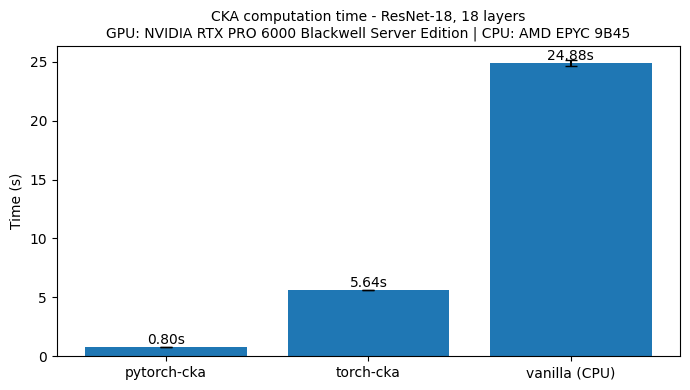

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index, summary["mean (s)"], yerr=summary["std (s)"], capsize=4)
for i, mean in enumerate(summary["mean (s)"]):
    ax.text(i, mean, f"{mean:.2f}s", ha="center", va="bottom")
ax.set_ylabel("Time (s)")
ax.set_title(
    f"CKA computation time - ResNet-18, {len(LAYERS)} layers\n"
    f"GPU: {torch.cuda.get_device_name(device)} | CPU: {CPU_NAME}",
    fontsize=10,
)
fig.tight_layout()
plt.show()